In [67]:
# --- Orchestrator-Worker Workflow ---
# Uses LangGraph's Send API for dynamic parallelism:
#   1. Orchestrator plans article sections
#   2. Send() spawns one worker per section (parallel)
#   3. Workers write sections concurrently
#   4. Synthesizer combines all sections and refines the article
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
import operator
from langgraph.graph.message import add_messages
from langgraph.types import Send
from langgraph.graph import StateGraph, END, START
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display, Markdown
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.messages import BaseMessage
from langchain_core.tools import tool

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

### **Orchestrator-Worker Agents: The Dynamic Version of Agents Parallelization**

In [68]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [69]:
# loadding Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [70]:
class Section(BaseModel):
    title: str = Field(..., description="Title of the section, e.g., 'Early Life', 'Major Achievements'.")
    description: str = Field(..., description="Brief overview of what should be covered in this section.")

In [71]:
class OutlinePlan(BaseModel):
    sections: List[Section] = Field(..., description="Dynamically planned sections for the scientist report.")

In [72]:
class ScientistInput(BaseModel):
    scientist: str = Field(min_length=3, max_length=100, description="The name of the scientist")

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value

In [73]:
class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined and synthesized final article under 1000 words.")

In [74]:
# Structured LLMs 
planner_llm = google_llm.with_structured_output(OutlinePlan)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

In [75]:
# Shared Main Graph State: Orchestrator State
class State(TypedDict):
    input: str
    scientist: NotRequired[str]
    sections: NotRequired[List[Section]]
    # Key reducer operator.add allows parallel workers to append outputs safetly
    completed_sections: Annotated[List[str], add] # expects a list of strings
    article: NotRequired[str]
    refined_article: NotRequired[str]

In [76]:
# Individual Worker State
class WorkerState(TypedDict):
    scientist: str
    section: Section

In [77]:
# Extracts the scientist's name from the user input via LLM
def scientist_name_extraction(state:State):
    # Extract the scientist's name from the input
    prompt = PromptTemplate.from_template(
    """Extract the scientist's name from the input provided by the user. 
    The input is: {input}.
    """
    )

    extraction_data  = {"input": state["input"]}
    extraction_chain  = prompt | google_llm
    response = extraction_chain.invoke(extraction_data)

    try:
        validated = ScientistInput.model_validate(
                    {
                    "scientist": response.content.strip()
                    }
        )
        # Assuming the response contains the extracted name in a field called 'content'
        return {"scientist": validated.scientist}

    except ValidationError as e:
        print(e.errors()[0]["msg"])

In [78]:
# Dynamically plans article sections using structured LLM output
def orchestrator(state: State):
    """
    Orchestrator: Dynamically breaks down the topic into 3-5 key sections
    tailored to the specific scientist (e.g. Early Life, Theories, Impact).
    """
    plan = planner_llm.invoke([
        SystemMessage(content="""You are an expert editor. Create an outline plan of 2 distinct sections for an article about the given scientist.
        Which covers the history and the achievements of the scientist
        """),
        HumanMessage(content=f"Scientist: {state['scientist']}")
    ])

    # Initialise state fields
    return {
        "sections": plan.sections,
        "completed_sections": []
    }

In [79]:
def worker_section_writer(state: WorkerState):
    """
    Worker: Executes a single section task generated by the orchestrator.
    Executes in parallel per section via Send API.
    """
    prompt = PromptTemplate.from_template(
        """Write a comprehensive section for an article about {scientist}.
        Section Title: {title}
        Section Focus: {description}
        
        Write only the section content in clear markdown. Do not include extra introductions or intros.
        """
    )
    
    chain = prompt | google_llm
    response = chain.invoke({
        "scientist": state["scientist"],
        "title": state["section"].title,
        "description": state["section"].description
    })
    
    formatted_section = f"### {state['section'].title}\n\n{response.content}"
    
    # Reducer appends this entry into state["completed_sections"]
    return {"completed_sections": [formatted_section]}

In [104]:
# Merges all worker-written sections into a single article, optionally refining if >1000 words
def synthesizer(state: State):
    """
    Synthesizer: Takes all completed section outputs from parallel workers,
    combines them, and applies word-length checks before optionally refining.
    """
    completed_sections = state.get("completed_sections", [])
    
    # 1. Guard check: Ensure worker outputs exist
    if not completed_sections:
        return {
            "article": "",
            "refined_article": "Error: Article was not generated properly."
        }

    # 2. Combine section outputs into full draft
    generated_article = "\n\n".join(completed_sections)
    article_length = len(generated_article.split())

    # 3. Branching logic based on word count
    if article_length > 1000:
        prompt = PromptTemplate.from_template(
            """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
            It should be concise and clear, and should not lose the main points of the article. 
            Final Article must be in Markdown format with different sections. For example;
            ## **Title**

            ### **History**

            ### **Achievements**

            ### **Main Contributions**
            
            ## **Conclusion**

            This is just an example you can modify
            
            You must give the article in Markdown format
            """
        )
        refined_article_data = {
            "scientist": state["scientist"], 
            "article": generated_article
        }
        refined_article_chain = prompt | refined_article_llm
        response = refined_article_chain.invoke(refined_article_data)

        # Null check to prevent 'NoneType' object has no attribute 'refined_article'
        if response and hasattr(response, "refined_article") and response.refined_article:
            refined_text = response.refined_article
        else:
            print("Warning: Structured output returned None. Falling back to generated draft.")
            refined_text = generated_article

        return {
            "article": generated_article,
            "refined_article": refined_text
        }
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {
            "article": generated_article,
            "refined_article": generated_article
        }

In [105]:
# Uses Send API to spawn parallel worker nodes, one per planned section
def assign_workers(state: State):
    """
    Conditional edge function that uses Send API to dynamically 
    spawn 'worker_section_writer' nodes for every planned section.
    """
    return [
        Send(
            "worker_section_writer", 
            {
                "scientist": state["scientist"], 
                "section": section
            }
        ) 
        for section in state["sections"]
    ]

In [106]:
# Assembles the full graph: extraction -> orchestrator -> Send() -> workers -> synthesizer
def build_orchestrator_worker_graph():
    workflow = StateGraph(State)

    # Add Nodes
    workflow.add_node("scientist_name_extraction", scientist_name_extraction)
    workflow.add_node("orchestrator",orchestrator)
    workflow.add_node("worker_section_writer", worker_section_writer)
    workflow.add_node("synthesizer", synthesizer)

    # Static Edges
    workflow.add_edge(START, "scientist_name_extraction")
    workflow.add_edge("scientist_name_extraction","orchestrator")

    # Orchestrator --> Dynamic Parallel Workers via Send()
    workflow.add_conditional_edges(
        "orchestrator",
        assign_workers,
        ["worker_section_writer"]
    )

    # Workers --> Synthesizer --> END
    workflow.add_edge("worker_section_writer","synthesizer")
    workflow.add_edge("synthesizer", END)

    return workflow.compile()

In [107]:
graph = build_orchestrator_worker_graph()

In [108]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

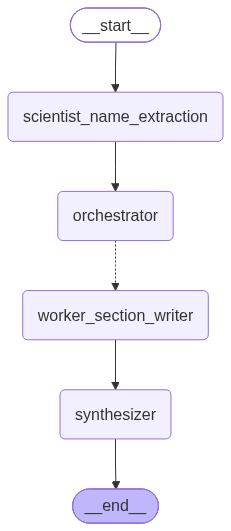

In [109]:
graph_visualiser(graph)

In [116]:
results = graph.invoke({
    "input": "Write an in-depth article about Stephen William Hawking"
    # "input": "Write an in-depth article about Marie Curie"
})

In [117]:
results

{'input': 'Write an in-depth article about Stephen William Hawking',
 'scientist': 'Stephen William Hawking',
 'sections': [Section(title='Early Life and Academic Journey', description="This section will detail Stephen Hawking's early life, education, and the onset and progression of his motor neuron disease, highlighting how he continued his academic pursuits despite his physical challenges."),
  Section(title='Groundbreaking Contributions to Physics and Cosmology', description="This section will focus on Stephen Hawking's major scientific achievements, including his work on black holes, singularity theorems, Hawking radiation, and his efforts to popularize science through his books and public lectures.")],
 'completed_sections': ['### Early Life and Academic Journey\n\nStephen William Hawking was born on January 8, 1942, in Oxford, England, precisely 300 years after the death of Galileo Galilei. His parents, Frank and Isobel Hawking, were both Oxford graduates; his father was a medic

In [118]:
list(results.keys())

['input',
 'scientist',
 'sections',
 'completed_sections',
 'article',
 'refined_article']

In [119]:
for key,value in results.items():
    print(f"{key}\n{value}\n")

input
Write an in-depth article about Stephen William Hawking

scientist
Stephen William Hawking

sections
[Section(title='Early Life and Academic Journey', description="This section will detail Stephen Hawking's early life, education, and the onset and progression of his motor neuron disease, highlighting how he continued his academic pursuits despite his physical challenges."), Section(title='Groundbreaking Contributions to Physics and Cosmology', description="This section will focus on Stephen Hawking's major scientific achievements, including his work on black holes, singularity theorems, Hawking radiation, and his efforts to popularize science through his books and public lectures.")]

completed_sections
['### Early Life and Academic Journey\n\nStephen William Hawking was born on January 8, 1942, in Oxford, England, precisely 300 years after the death of Galileo Galilei. His parents, Frank and Isobel Hawking, were both Oxford graduates; his father was a medical researcher, and his

In [125]:
for section in results['sections']:
    print(section.description)


This section will detail Stephen Hawking's early life, education, and the onset and progression of his motor neuron disease, highlighting how he continued his academic pursuits despite his physical challenges.
This section will focus on Stephen Hawking's major scientific achievements, including his work on black holes, singularity theorems, Hawking radiation, and his efforts to popularize science through his books and public lectures.


In [126]:
sections_total = 0
for section_num in range(len(results['sections'])):
    sections_total += 1

print(f"Total Sections/Workers present are: {sections_total}")

Total Sections/Workers present are: 2


In [121]:
Markdown(results["refined_article"])

## **Stephen William Hawking: A Legacy of Mind Over Matter**

Stephen William Hawking, born on January 8, 1942, was a towering figure in theoretical physics and cosmology, whose life and work profoundly reshaped our understanding of the universe despite facing immense physical challenges. His journey from an inquisitive child to a global scientific icon is a testament to human intellect and resilience.

### **Early Life and Academic Path**

Hawking was born in Oxford, England, to academically inclined parents. He spent much of his childhood in St Albans, known for his curiosity, often disassembling household items. At 17, he earned a scholarship to Oxford University, where he pursued physics, finding it "ridiculously easy" and engaging in extracurriculars like rowing. He graduated in 1962 with a first-class honours degree.

He then moved to Trinity Hall, Cambridge, for postgraduate studies in cosmology. It was during this period, in his early twenties, that he began experiencing symptoms of a debilitating illness, including clumsiness and slurred speech.

### **Diagnosis and Unyielding Spirit**

In January 1963, shortly after his 21st birthday, Hawking was diagnosed with amyotrophic lateral sclerosis (ALS), a motor neuron disease, and given only a few years to live. This devastating news initially plunged him into depression. However, meeting Jane Wilde, whom he married in 1965, provided him with renewed purpose. Despite the rapid progression of his disease, which soon confined him to a wheelchair, his intellect remained sharp. Inspired by Roger Penrose's work, he poured his energy into research, completing his groundbreaking PhD thesis, "Properties of Expanding Universes," in 1966. This early determination became a hallmark of his life.

### **Groundbreaking Contributions to Physics and Cosmology**

Hawking's scientific contributions fundamentally altered our perception of the cosmos:

*   **Singularity Theorems:** In the 1960s, collaborating with Roger Penrose, Hawking applied general relativity to demonstrate that the universe must have originated from a singularity (the Big Bang) and that black holes inevitably lead to singularities. This work provided a robust mathematical foundation for the Big Bang theory and the existence of black holes.

*   **Hawking Radiation:** His most revolutionary achievement came in 1974 with the prediction of Hawking radiation. He theorized that due to quantum fluctuations near a black hole's event horizon, virtual particle-antiparticle pairs are created. If one particle falls into the black hole while the other escapes, it appears as if the black hole is emitting radiation, causing it to slowly lose mass and eventually evaporate. This concept brilliantly linked general relativity, quantum mechanics, and thermodynamics, suggesting black holes are not entirely "black" and introducing the profound "information paradox."

*   **Cosmology:** In the 1980s, with James Hartle, he proposed the "no-boundary proposal," suggesting that the universe has no initial singularity in imaginary time, implying a self-contained universe without a traditional beginning or end. This offered a potential path to unify quantum mechanics and general relativity in the context of the early universe.

### **Popularization of Science**

Beyond his theoretical brilliance, Hawking was an extraordinary popularizer of science. He believed in making complex scientific ideas accessible to a global audience. His most famous work, *A Brief History of Time* (1988), became a worldwide bestseller, demystifying concepts like black holes, the Big Bang, and the nature of time for millions. Through this and other books, lectures, and documentaries, he inspired countless individuals, fostering a greater appreciation for physics and cosmology and ensuring his insights transcended academic circles.

## **Conclusion**

Stephen Hawking's life was a remarkable journey of intellectual triumph over adversity. His profound contributions to theoretical physics, particularly his work on black holes and the origins of the universe, alongside his unparalleled ability to communicate complex science to the public, cemented his legacy as one of the most influential scientists of his time. He proved that the human spirit, driven by curiosity and determination, can overcome the most formidable challenges to explore the deepest mysteries of the cosmos.